# 🗑️ WasteVision — Garbage Detection with YOLO26

**Goal:** Fine-tune a **YOLO26** model on the Garbage Classification dataset to detect
and localise **6 waste categories** in real-world images, enabling automated waste
sorting and recycling compliance monitoring.

**Why YOLO26?**
YOLO26 is Ultralytics' 2026 state-of-the-art one-stage detector. Its improved
anchor-free head, advanced feature-pyramid neck, and optimised depthwise-separable
backbone achieve higher mAP than YOLOv8/v9/v11 at the same FLOPs — ideal for
real-time waste-sorting systems where accuracy and speed are equally critical.

**Model variant:** `yolo26s` — best accuracy/speed tradeoff for Colab T4 (15 GB VRAM)
with this dataset size. Upgrade to `yolo26m` if A100 is available.

**Dataset:** Garbage Classification — 6 classes, ~15 000 annotated images (YOLO format)

**Pipeline:**
```
1.  Environment Setup & Imports
2.  Dataset Download  (Roboflow)
3.  Configuration
4.  Utilities
5.  Dataset Exploration
6.  Dataset Cleaning
7.  Dataset Validation → data.yaml
8.  Data Augmentation config
9-A. Hyperparameter Optimisation  (Optuna)
9.  Training  (YOLO26 — 100 epochs)
10. Evaluation  (mAP@50, mAP@50:95, per-class AP)
11. Error Analysis  (FP / FN gallery)
12. Inference Testing  (latency benchmark + visual predictions)
13. Export Model  (ONNX opset 17 + metadata JSON)
```

> **Runtime:** GPU required (T4 / A100). Enable via *Runtime → Change runtime type → GPU*.


---
# 1 · Environment Setup & Imports


In [ ]:
!pip install -q roboflow ultralytics seaborn pandas onnxruntime optuna


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.0/46.0 kB 917.8 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 302.3/302.3 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 19.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.1/23.1 MB 27.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 13.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 265.9/265.9 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.2/53.2 kB 831.8 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 15.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 39.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.2/66.2 kB 1.3 MB/s eta 0:00:00


In [ ]:
import hashlib, json, random, shutil, time, warnings
from collections import Counter, defaultdict
from dataclasses import dataclass, field
from datetime import datetime, timezone
from pathlib import Path
from typing import Any, Dict, List, Optional

import cv2
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import seaborn as sns
import torch
import yaml
from roboflow import Roboflow
from tqdm import tqdm
from ultralytics import YOLO
import onnxruntime as ort

optuna.logging.set_verbosity(optuna.logging.WARNING)
warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi': 120, 'font.size': 10})

print(f'PyTorch    : {torch.__version__}')
print(f'CUDA avail : {torch.cuda.is_available()}')
if torch.cuda.is_available():
    print(f'GPU        : {torch.cuda.get_device_name(0)}')
    print(f'VRAM       : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')
print('All imports OK')


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart#ultralytics-settings.
PyTorch    : 2.11.0+cpu
CUDA avail : False
All imports OK


---
# 2 · Dataset Download

Dataset: **Garbage Classification 3** — [Roboflow Universe](https://universe.roboflow.com)

**6 waste categories** with YOLO bounding-box annotations:
`biodegradable` · `cardboard` · `glass` · `metal` · `paper` · `plastic`

Downloaded in **yolo26** format — the native annotation format expected by YOLO26.


In [ ]:
rf = Roboflow(api_key="WaDbico9bVS8c5qVkryA")
project = rf.workspace("waste-classification-jl6nz").project("garbage-classification-3-ymuqp")
version = project.version(3)
dataset = version.download("yolo26")

DATASET_ROOT = Path(dataset.location)
print(f'\nDataset root: {DATASET_ROOT}')
print('Contents:')
for item in sorted(DATASET_ROOT.iterdir()):
    print(f'  {"DIR " if item.is_dir() else "FILE"}  {item.name}')


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to GARBAGE-CLASSIFICATION-3-3 in yolo26:: 100%|██████████| 35581/35581 [00:04<00:00, 7778.57it/s] 



Dataset root: /content/GARBAGE-CLASSIFICATION-3-3
Contents:
  FILE  README.dataset.txt
  FILE  README.roboflow.txt
  FILE  data.yaml
  DIR   test
  DIR   train
  DIR   valid


---
# 3 · Configuration


In [ ]:
# ── Garbage waste categories (6 classes) ─────────────────────────────────────
# Ordered to match Roboflow's alphabetical label assignment
NORMALIZED_CLASSES: List[str] = [
    'biodegradable',  # 0  organic / food / plant waste
    'cardboard',      # 1  corrugated / paper board
    'glass',          # 2  bottles, jars, containers
    'metal',          # 3  cans, tins, foil
    'paper',          # 4  newspapers, magazines, office paper
    'plastic',        # 5  bags, bottles, packaging
]

NUM_CLASSES = len(NORMALIZED_CLASSES)
CLASS_TO_ID = {cls: i for i, cls in enumerate(NORMALIZED_CLASSES)}
ID_TO_CLASS = {i: cls for i, cls in enumerate(NORMALIZED_CLASSES)}

# Colour palette for visualisations
CLASS_COLORS: Dict[str, str] = {
    'biodegradable': '#27ae60',  # green  — organic
    'cardboard':     '#e67e22',  # orange — cardboard
    'glass':         '#3498db',  # blue   — glass
    'metal':         '#95a5a6',  # silver — metal
    'paper':         '#f1c40f',  # yellow — paper
    'plastic':       '#e74c3c',  # red    — plastic
}

print(f'  ID   CLASS            COLOUR')
print(f'  {"="*40}')
for i, cls in ID_TO_CLASS.items():
    print(f'  {i}    {cls:<16s}  {CLASS_COLORS[cls]}')


  ID   CLASS            COLOUR
  0    biodegradable     #27ae60
  1    cardboard         #e67e22
  2    glass             #3498db
  3    metal             #95a5a6
  4    paper             #f1c40f
  5    plastic           #e74c3c


In [ ]:
IMAGES_TRAIN = DATASET_ROOT / 'train' / 'images'
LABELS_TRAIN = DATASET_ROOT / 'train' / 'labels'
IMAGES_VALID = DATASET_ROOT / 'valid' / 'images'
LABELS_VALID = DATASET_ROOT / 'valid' / 'labels'
IMAGES_TEST  = DATASET_ROOT / 'test'  / 'images'
LABELS_TEST  = DATASET_ROOT / 'test'  / 'labels'

PLOTS_DIR   = Path('plots');   PLOTS_DIR.mkdir(parents=True, exist_ok=True)
EXPORTS_DIR = Path('exports'); EXPORTS_DIR.mkdir(parents=True, exist_ok=True)
IMAGE_EXTS  = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}

# ── Model & training hyperparameters ──────────────────────────────────────────
# yolo26s: best balance for T4 (15 GB VRAM) with this dataset.
# Upgrade to yolo26m if running on A100 for +2-3 mAP with similar training time.
MODEL_NAME = 'yolo26s.pt'
IMAGE_SIZE = 640
BATCH_SIZE = 16
EPOCHS     = 100
PATIENCE   = 20       # early stopping patience
LR0        = 0.01     # initial learning rate
LRF        = 0.01     # final LR = LR0 * LRF
OPTIMIZER  = 'AdamW'
DEVICE     = 0 if torch.cuda.is_available() else 'cpu'
SEED       = 42
WORKERS    = 4
CONF       = 0.35     # confidence threshold for inference
IOU        = 0.45     # NMS IoU threshold
RUN_NAME   = f'waste_yolo26s_{datetime.now().strftime("%Y%m%d_%H%M")}'

print(f'Model      : {MODEL_NAME}')
print(f'Device     : {DEVICE}')
print(f'Image size : {IMAGE_SIZE}')
print(f'Batch size : {BATCH_SIZE}')
print(f'Run name   : {RUN_NAME}')


Model      : yolo26s.pt
Device     : cpu
Image size : 640
Batch size : 16
Run name   : waste_yolo26s_20260830_2030


---
# 4 · Utilities


In [ ]:
@dataclass
class YOLOAnnotation:
    """Single bounding-box annotation in YOLO normalised format."""
    class_id: int
    cx: float
    cy: float
    w:  float
    h:  float
    source_line: str = ''

    @property
    def is_valid(self) -> bool:
        return (
            0 <= self.class_id < NUM_CLASSES
            and 0.0 <= self.cx <= 1.0 and 0.0 <= self.cy <= 1.0
            and 0.0 <  self.w  <= 1.0 and 0.0 <  self.h  <= 1.0
        )


@dataclass
class DatasetStats:
    """Statistics for one dataset split."""
    split:              str                       = ''
    total_images:       int                       = 0
    valid_images:       int                       = 0
    corrupted_images:   List[str]                 = field(default_factory=list)
    missing_labels:     List[str]                 = field(default_factory=list)
    empty_annotations:  List[str]                 = field(default_factory=list)
    invalid_annotations:List[str]                 = field(default_factory=list)
    duplicate_hashes:   Dict[str, List[str]]      = field(default_factory=dict)
    class_counts:       Counter                   = field(default_factory=Counter)
    resolution_list:    List[tuple]               = field(default_factory=list)
    bbox_widths:        List[float]               = field(default_factory=list)
    bbox_heights:       List[float]               = field(default_factory=list)

    def summary(self) -> Dict[str, Any]:
        dup_imgs = sum(len(v) - 1 for v in self.duplicate_hashes.values())
        total_ann = sum(self.class_counts.values())
        return {
            'split':              self.split,
            'total_images':       self.total_images,
            'valid_images':       self.valid_images,
            'corrupted_images':   len(self.corrupted_images),
            'missing_labels':     len(self.missing_labels),
            'empty_annotations':  len(self.empty_annotations),
            'invalid_annotations':len(self.invalid_annotations),
            'duplicate_groups':   len(self.duplicate_hashes),
            'total_annotations':  total_ann,
            'avg_ann_per_image':  round(total_ann / max(self.valid_images, 1), 2),
        }


print('YOLOAnnotation + DatasetStats defined.')


YOLOAnnotation + DatasetStats defined.


In [ ]:
def parse_yolo_label_file(label_path: Path) -> tuple[list, list]:
    """Parse a YOLO .txt label file. Returns (annotations, errors)."""
    annotations, errors = [], []
    if not label_path.exists():
        errors.append(f'Missing: {label_path}')
        return annotations, errors
    for i, line in enumerate(label_path.read_text(encoding='utf-8').splitlines()):
        line = line.strip()
        if not line:
            continue
        parts = line.split()
        if len(parts) != 5:
            errors.append(f'{label_path.name}:{i+1} expected 5 fields, got {len(parts)}')
            continue
        try:
            ann = YOLOAnnotation(
                class_id=int(parts[0]),
                cx=float(parts[1]), cy=float(parts[2]),
                w=float(parts[3]),  h=float(parts[4]),
                source_line=line,
            )
        except ValueError:
            errors.append(f'{label_path.name}:{i+1} non-numeric: {line!r}')
            continue
        if not ann.is_valid:
            errors.append(f'{label_path.name}:{i+1} out-of-range bbox')
        annotations.append(ann)
    return annotations, errors


def validate_image(image_path: Path) -> tuple[bool, str, tuple]:
    """Returns (is_valid, error_msg, (height, width))."""
    try:
        img = cv2.imread(str(image_path))
        if img is None:
            return False, 'Cannot read', (0, 0)
        h, w = img.shape[:2]
        ok = h > 0 and w > 0
        return ok, '' if ok else f'Zero dim {h}x{w}', (h, w)
    except Exception as e:
        return False, str(e), (0, 0)


def compute_image_hash(image_path: Path) -> str:
    return hashlib.md5(image_path.read_bytes()).hexdigest()


print('Helper functions defined.')


Helper functions defined.


In [ ]:
def compute_dataset_stats(
    images_dir: Path, labels_dir: Path,
    split: str = '', show_progress: bool = True,
) -> DatasetStats:
    """Scan a YOLO split and return rich statistics."""
    stats = DatasetStats(split=split)
    image_files = sorted(p for p in images_dir.iterdir() if p.suffix.lower() in IMAGE_EXTS)
    stats.total_images = len(image_files)
    hash_to_paths: Dict[str, List[str]] = defaultdict(list)

    for img_path in tqdm(image_files, desc=f'Scanning {split}', disable=not show_progress):
        valid, err, (h, w) = validate_image(img_path)
        if not valid:
            stats.corrupted_images.append(str(img_path))
            continue
        stats.valid_images += 1
        stats.resolution_list.append((h, w))
        hash_to_paths[compute_image_hash(img_path)].append(str(img_path))

        label_path = labels_dir / (img_path.stem + '.txt')
        if not label_path.exists():
            stats.missing_labels.append(str(img_path))
            continue
        annotations, errors = parse_yolo_label_file(label_path)
        stats.invalid_annotations.extend(errors)
        if not annotations:
            stats.empty_annotations.append(str(img_path))
        for ann in annotations:
            if ann.is_valid:
                stats.class_counts[ann.class_id] += 1
                stats.bbox_widths.append(ann.w)
                stats.bbox_heights.append(ann.h)

    stats.duplicate_hashes = {h: p for h, p in hash_to_paths.items() if len(p) > 1}
    return stats


print('compute_dataset_stats defined.')


compute_dataset_stats defined.


In [ ]:
def class_counts_by_name(stats: DatasetStats) -> Dict[str, int]:
    return {ID_TO_CLASS.get(k, f'id_{k}'): v for k, v in stats.class_counts.items()}


def plot_class_distribution(
    counts: Dict[str, int], title: str = 'Class Distribution',
    ax=None, save_path: Optional[Path] = None,
) -> plt.Figure:
    """Horizontal bar chart coloured per waste class."""
    if not counts:
        print(f'[skip] {title} — no data'); return plt.figure()
    classes = list(counts.keys())
    values  = list(counts.values())
    colors  = [CLASS_COLORS.get(c, '#95a5a6') for c in classes]
    standalone = ax is None
    if standalone:
        fig, ax = plt.subplots(figsize=(10, max(3, len(classes) * 0.6)))
    else:
        fig = ax.figure
    bars = ax.barh(classes, values, color=colors)
    ax.set_xlabel('Annotation count')
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.invert_yaxis()
    for bar, val in zip(bars, values):
        ax.text(bar.get_width() + max(values) * 0.01,
                bar.get_y() + bar.get_height() / 2,
                str(val), va='center', fontsize=8)
    if standalone:
        plt.tight_layout()
        if save_path:
            fig.savefig(save_path, bbox_inches='tight')
    return fig


print('Plotting utilities defined.')


Plotting utilities defined.


---
# 5 · Dataset Exploration

Scan all three splits (train / valid / test) and produce:
- **Per-split summary table** (images, annotations, quality issues)
- **Class distribution** — annotation counts per waste category
- **Per-class count comparison** table with imbalance ratio
- **Bounding-box size density map** (are objects small/medium/large?)
- **Image resolution histogram**
- **Annotated sample grid** — representative images with GT boxes drawn


In [ ]:
print('Scanning dataset splits (may take 1–3 min)...\n')

stats_train = compute_dataset_stats(IMAGES_TRAIN, LABELS_TRAIN, split='train')
stats_valid = compute_dataset_stats(IMAGES_VALID, LABELS_VALID, split='valid')
stats_test  = compute_dataset_stats(IMAGES_TEST,  LABELS_TEST,  split='test')
ALL_STATS   = [stats_train, stats_valid, stats_test]

print('\nScan complete.')


Scanning dataset splits (may take 1–3 min)...



Scanning test: 100%|██████████| 1042/1042 [00:02<00:00, 468.59it/s]


Scan complete.


In [ ]:
# 5.1  Per-split summary table
rows = []
for s in ALL_STATS:
    sm = s.summary()
    rows.append({
        'Split':               sm['split'].upper(),
        'Total images':        sm['total_images'],
        'Valid images':        sm['valid_images'],
        'Corrupted':           sm['corrupted_images'],
        'Missing labels':      sm['missing_labels'],
        'Empty annotations':   sm['empty_annotations'],
        'Invalid annotations': sm['invalid_annotations'],
        'Duplicate groups':    sm['duplicate_groups'],
        'Total annotations':   sm['total_annotations'],
        'Avg ann/image':       sm['avg_ann_per_image'],
    })

df_summary = pd.DataFrame(rows).set_index('Split')
print('=' * 70)
print('DATASET QUALITY SUMMARY')
print('=' * 70)
print(df_summary.to_string())
print(f'\nGrand total images     : {sum(s.total_images for s in ALL_STATS):,}')
print(f'Grand total annotations: {sum(sum(s.class_counts.values()) for s in ALL_STATS):,}')


DATASET QUALITY SUMMARY
       Total images  Valid images  Corrupted  Missing labels  Empty annotations  Invalid annotations  Duplicate groups  Total annotations  Avg ann/image
Split                                                                                                                                                   
TRAIN         14648         14648          0               0                  0                    0                 0             102779           7.02
VALID          2098          2098          0               0                  0                    0                 0              18910           9.01
TEST           1042          1042          0               0                  0                    0                 0               3562           3.42

Grand total images     : 17,788
Grand total annotations: 125,251


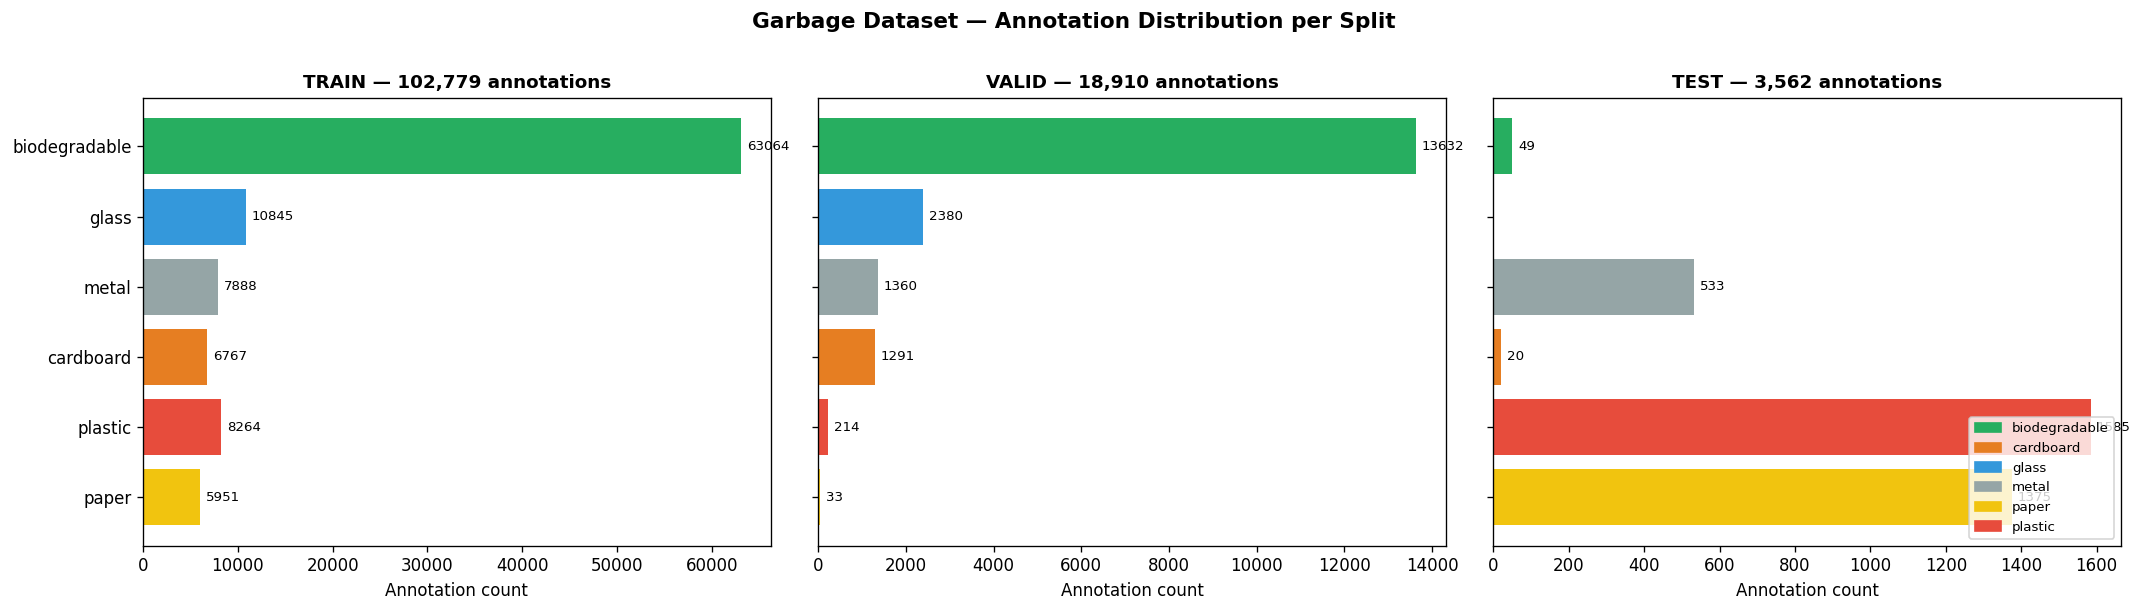

Saved: plots/class_distribution.png


In [ ]:
# 5.2  Class distribution — all splits side by side
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for ax, s in zip(axes, ALL_STATS):
    plot_class_distribution(
        class_counts_by_name(s),
        title=f"{s.split.upper()} — {sum(s.class_counts.values()):,} annotations",
        ax=ax,
    )
legend_patches = [mpatches.Patch(color=CLASS_COLORS[c], label=c) for c in NORMALIZED_CLASSES]
axes[-1].legend(handles=legend_patches, loc='lower right', fontsize=8)
plt.suptitle('Garbage Dataset — Annotation Distribution per Split',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
fig.savefig(PLOTS_DIR / 'class_distribution.png', bbox_inches='tight')
plt.show()
print(f'Saved: {PLOTS_DIR}/class_distribution.png')


In [ ]:
# 5.3  Per-class count comparison table + imbalance ratio
class_df_data = {}
for s in ALL_STATS:
    class_df_data[s.split.upper()] = {ID_TO_CLASS.get(k, f'id_{k}'): v
                                       for k, v in s.class_counts.items()}

df_classes = (
    pd.DataFrame(class_df_data, index=NORMALIZED_CLASSES)
    .fillna(0).astype(int)
)
df_classes.index.name = 'Class'
df_classes['TOTAL'] = df_classes.sum(axis=1)
df_classes = df_classes.sort_values('TOTAL', ascending=False)

print(df_classes.to_string())

max_cnt = df_classes['TOTAL'].max()
min_cnt = df_classes['TOTAL'].min()
imbalance_ratio = max_cnt / max(min_cnt, 1)
print(f'\nClass imbalance ratio (max/min): {imbalance_ratio:.2f}x')
print(f'Max class: {df_classes["TOTAL"].idxmax()}  ({max_cnt:,} annotations)')
print(f'Min class: {df_classes["TOTAL"].idxmin()}  ({min_cnt:,} annotations)')
if imbalance_ratio > 3.0:
    print('    Significant imbalance — cls_pw (class pixel weights) recommended in training.')
elif imbalance_ratio > 1.5:
    print('    Moderate imbalance — monitor per-class AP during training.')
else:
    print('    Dataset is well-balanced.')


               TRAIN  VALID  TEST  TOTAL
Class                                   
biodegradable  63064  13632    49  76745
glass          10845   2380     0  13225
plastic         8264    214  1585  10063
metal           7888   1360   533   9781
cardboard       6767   1291    20   8078
paper           5951     33  1375   7359

Class imbalance ratio (max/min): 10.43x
Max class: biodegradable  (76,745 annotations)
Min class: paper  (7,359 annotations)
    Significant imbalance — cls_pw (class pixel weights) recommended in training.


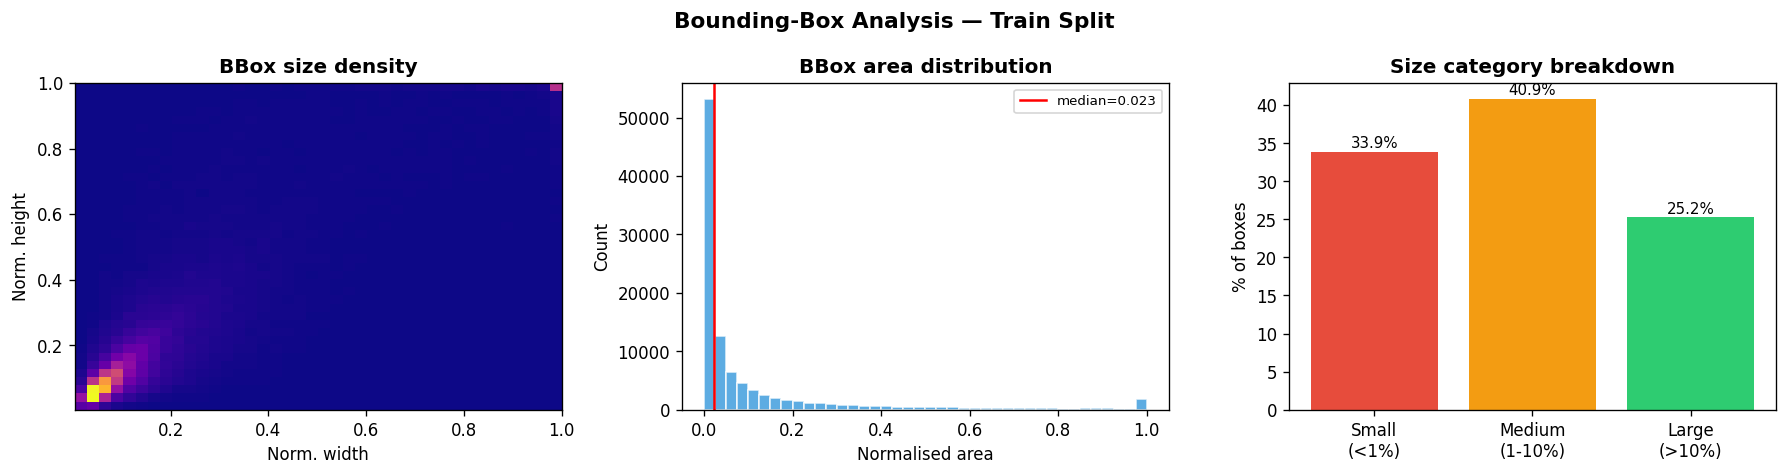

  Small (<1% area) : 33.9%
  Medium (1-10%)   : 40.9%
  Large  (>10%)    : 25.2%
Saved: plots/bbox_analysis.png


In [ ]:
# 5.4  Bounding-box size density map (train split)
if stats_train.bbox_widths:
    bw = np.array(stats_train.bbox_widths)
    bh = np.array(stats_train.bbox_heights)
    area = bw * bh  # normalised area

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    axes[0].hist2d(bw, bh, bins=40, cmap='plasma')
    axes[0].set_xlabel('Norm. width'); axes[0].set_ylabel('Norm. height')
    axes[0].set_title('BBox size density', fontweight='bold')

    axes[1].hist(area, bins=40, color='#3498db', alpha=0.8, edgecolor='white')
    axes[1].axvline(np.median(area), color='red', lw=1.5, label=f'median={np.median(area):.3f}')
    axes[1].set_xlabel('Normalised area'); axes[1].set_ylabel('Count')
    axes[1].set_title('BBox area distribution', fontweight='bold')
    axes[1].legend(fontsize=8)

    small  = (area < 0.01).mean() * 100
    medium = ((area >= 0.01) & (area < 0.1)).mean() * 100
    large  = (area >= 0.1).mean() * 100
    axes[2].bar(['Small\n(<1%)', 'Medium\n(1-10%)', 'Large\n(>10%)'],
                [small, medium, large],
                color=['#e74c3c', '#f39c12', '#2ecc71'])
    axes[2].set_ylabel('% of boxes')
    axes[2].set_title('Size category breakdown', fontweight='bold')
    for i, v in enumerate([small, medium, large]):
        axes[2].text(i, v + 0.5, f'{v:.1f}%', ha='center', fontsize=9)

    plt.suptitle('Bounding-Box Analysis — Train Split', fontsize=13, fontweight='bold')
    plt.tight_layout()
    fig.savefig(PLOTS_DIR / 'bbox_analysis.png', bbox_inches='tight')
    plt.show()
    print(f'  Small (<1% area) : {small:.1f}%')
    print(f'  Medium (1-10%)   : {medium:.1f}%')
    print(f'  Large  (>10%)    : {large:.1f}%')
    print(f'Saved: {PLOTS_DIR}/bbox_analysis.png')


Unique resolutions (train): 1
Top 10:
       640x640  x14648


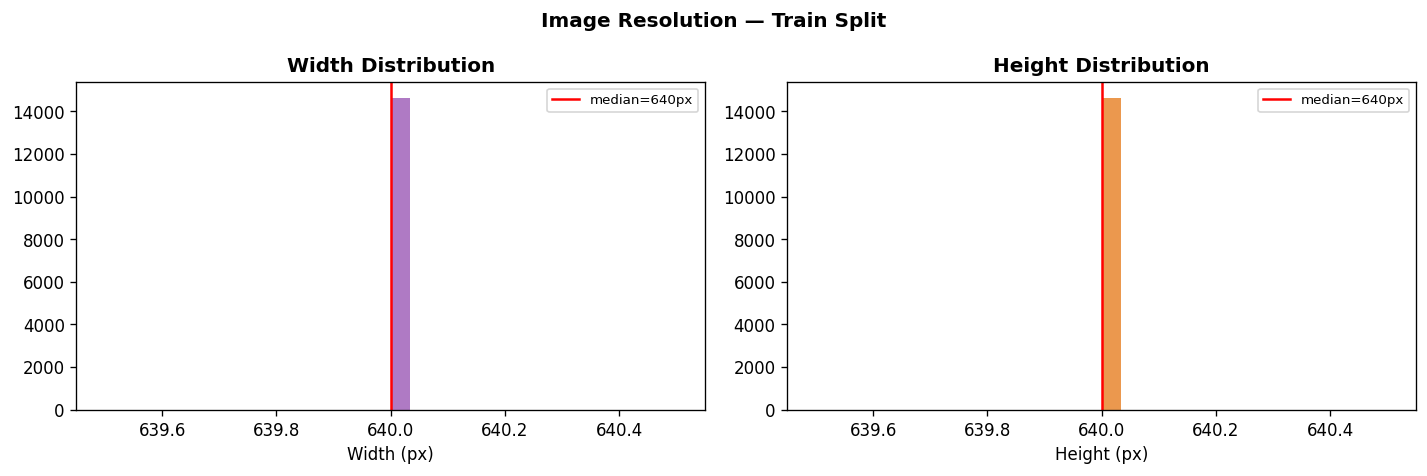

Saved: plots/image_resolutions.png


In [ ]:
# 5.5  Image resolution histogram
if stats_train.resolution_list:
    heights = [r[0] for r in stats_train.resolution_list]
    widths  = [r[1] for r in stats_train.resolution_list]
    from collections import Counter as _C
    unique_res = _C(f'{w}x{h}' for h, w in stats_train.resolution_list)

    print(f'Unique resolutions (train): {len(unique_res)}')
    print('Top 10:')
    for res, cnt in unique_res.most_common(10):
        print(f'  {res:>12s}  x{cnt}')

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    ax1.hist(widths,  bins=30, color='#9b59b6', alpha=0.8)
    ax1.axvline(np.median(widths), color='red', lw=1.5, label=f'median={int(np.median(widths))}px')
    ax1.set_xlabel('Width (px)'); ax1.set_title('Width Distribution', fontweight='bold')
    ax1.legend(fontsize=8)

    ax2.hist(heights, bins=30, color='#e67e22', alpha=0.8)
    ax2.axvline(np.median(heights), color='red', lw=1.5, label=f'median={int(np.median(heights))}px')
    ax2.set_xlabel('Height (px)'); ax2.set_title('Height Distribution', fontweight='bold')
    ax2.legend(fontsize=8)

    plt.suptitle('Image Resolution — Train Split', fontweight='bold')
    plt.tight_layout()
    fig.savefig(PLOTS_DIR / 'image_resolutions.png', bbox_inches='tight')
    plt.show()
    print(f'Saved: {PLOTS_DIR}/image_resolutions.png')


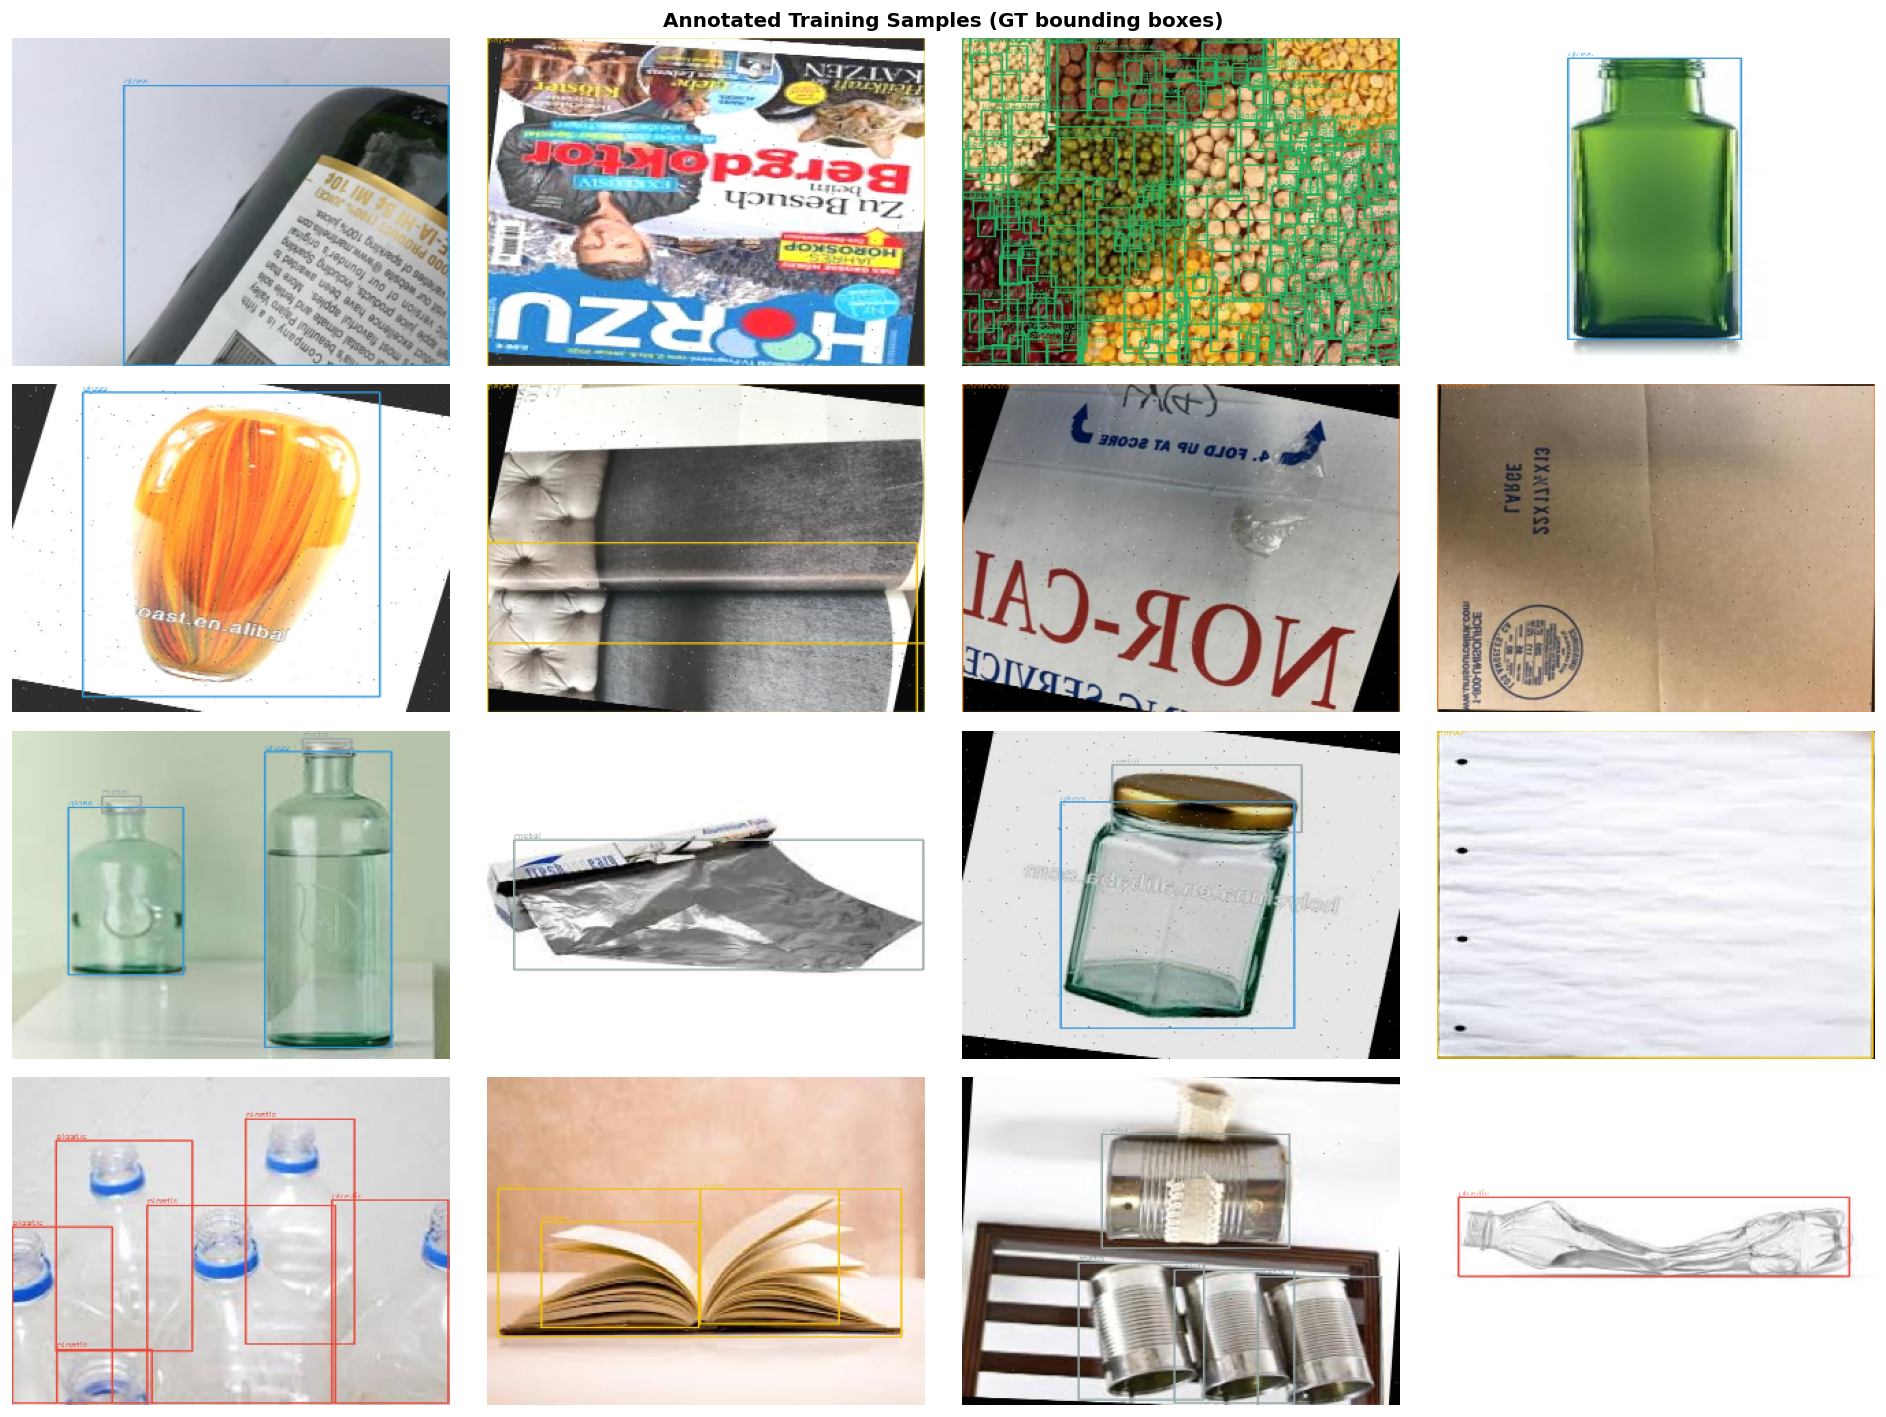

Saved: plots/sample_grid.png


In [ ]:
# 5.6  Annotated sample grid — 16 random training images with GT bboxes
image_files = sorted(p for p in IMAGES_TRAIN.iterdir() if p.suffix.lower() in IMAGE_EXTS)
samples = random.sample(image_files, min(16, len(image_files)))

grid_imgs = []
for img_path in samples:
    img_bgr = cv2.imread(str(img_path))
    if img_bgr is None: continue
    h, w = img_bgr.shape[:2]
    label_path = LABELS_TRAIN / (img_path.stem + '.txt')
    anns, _ = parse_yolo_label_file(label_path)
    for ann in anns:
        if not ann.is_valid: continue
        cls_name = ID_TO_CLASS.get(ann.class_id, 'unknown')
        col_hex  = CLASS_COLORS.get(cls_name, '#ffffff')
        col_bgr  = tuple(int(col_hex.lstrip('#')[i:i+2], 16) for i in (4, 2, 0))
        x1 = int((ann.cx - ann.w/2) * w);  y1 = int((ann.cy - ann.h/2) * h)
        x2 = int((ann.cx + ann.w/2) * w);  y2 = int((ann.cy + ann.h/2) * h)
        cv2.rectangle(img_bgr, (x1,y1), (x2,y2), col_bgr, 2)
        cv2.putText(img_bgr, cls_name, (x1, max(y1-4, 10)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.45, col_bgr, 1)
    img_rgb = cv2.cvtColor(cv2.resize(img_bgr, (320, 240)), cv2.COLOR_BGR2RGB)
    grid_imgs.append(img_rgb)

cols = 4; rows = (len(grid_imgs) + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(cols*4, rows*3))
axes = np.array(axes).flatten()
for i, (img, ax) in enumerate(zip(grid_imgs, axes)):
    ax.imshow(img); ax.axis('off')
for ax in axes[len(grid_imgs):]: ax.axis('off')
plt.suptitle('Annotated Training Samples (GT bounding boxes)', fontsize=12, fontweight='bold')
plt.tight_layout()
fig.savefig(PLOTS_DIR / 'sample_grid.png', bbox_inches='tight')
plt.show()
print(f'Saved: {PLOTS_DIR}/sample_grid.png')


---
# 6 · Dataset Cleaning

Remove or quarantine:
- Corrupted / unreadable images
- Exact duplicate images (same MD5 hash)
- Annotations with out-of-range bounding boxes

> Set `DRY_RUN = False` to apply changes permanently.


In [ ]:
# 6.1  Quality report
def print_quality_report(s: DatasetStats) -> None:
    dup_imgs = sum(len(v) - 1 for v in s.duplicate_hashes.values())
    print(f'\n  {s.split.upper()}')
    print(f'  Corrupted images     : {len(s.corrupted_images)}')
    print(f'  Missing label files  : {len(s.missing_labels)}')
    print(f'  Empty annotations    : {len(s.empty_annotations)}')
    print(f'  Invalid annotations  : {len(s.invalid_annotations)}')
    print(f'  Duplicate images     : {dup_imgs}  (keeping 1 per group)')

for s in ALL_STATS:
    print_quality_report(s)



  TRAIN
  Corrupted images     : 0
  Missing label files  : 0
  Empty annotations    : 0
  Invalid annotations  : 0
  Duplicate images     : 0  (keeping 1 per group)

  VALID
  Corrupted images     : 0
  Missing label files  : 0
  Empty annotations    : 0
  Invalid annotations  : 0
  Duplicate images     : 0  (keeping 1 per group)

  TEST
  Corrupted images     : 0
  Missing label files  : 0
  Empty annotations    : 0
  Invalid annotations  : 0
  Duplicate images     : 0  (keeping 1 per group)


In [ ]:
# 6.2  Remove corrupted images & paired labels
DRY_RUN = True   # <-- set False to actually delete files


def remove_corrupted(stats: DatasetStats, labels_dir: Path, dry_run: bool = True) -> int:
    removed = 0
    for img_str in stats.corrupted_images:
        img_p = Path(img_str)
        lbl_p = labels_dir / (img_p.stem + '.txt')
        if not dry_run:
            img_p.unlink(missing_ok=True)
            lbl_p.unlink(missing_ok=True)
        removed += 1
    return removed


totals = {
    s.split: remove_corrupted(s, DATASET_ROOT / s.split / 'labels', dry_run=DRY_RUN)
    for s in ALL_STATS
}
print(f'Corrupted removed (dry_run={DRY_RUN}): {totals}')


Corrupted removed (dry_run=True): {'train': 0, 'valid': 0, 'test': 0}


In [ ]:
# 6.3  Remove duplicate images
def remove_duplicates(stats: DatasetStats, labels_dir: Path, dry_run: bool = True) -> int:
    removed = 0
    for _, paths in stats.duplicate_hashes.items():
        for dup_str in paths[1:]:
            dup_p = Path(dup_str)
            lbl_p = labels_dir / (dup_p.stem + '.txt')
            if not dry_run:
                dup_p.unlink(missing_ok=True)
                lbl_p.unlink(missing_ok=True)
            removed += 1
    return removed


totals_dup = {
    s.split: remove_duplicates(s, DATASET_ROOT / s.split / 'labels', dry_run=DRY_RUN)
    for s in ALL_STATS
}
print(f'Duplicates removed (dry_run={DRY_RUN}): {totals_dup}')


Duplicates removed (dry_run=True): {'train': 0, 'valid': 0, 'test': 0}


In [ ]:
# 6.4  Clip / fix out-of-range bounding boxes
def clip_bbox(ann: YOLOAnnotation) -> YOLOAnnotation:
    return YOLOAnnotation(
        class_id=ann.class_id,
        cx=min(max(ann.cx, 0.0), 1.0), cy=min(max(ann.cy, 0.0), 1.0),
        w=min(max(ann.w, 1e-4), 1.0),  h=min(max(ann.h, 1e-4), 1.0),
        source_line=ann.source_line,
    )


def fix_label_file(label_path: Path, dry_run: bool = True) -> int:
    """Clip all out-of-range boxes in a label file. Returns number of fixed boxes."""
    annotations, errors = parse_yolo_label_file(label_path)
    fixed = sum(1 for a in annotations if not a.is_valid)
    if fixed > 0 and not dry_run:
        clipped = [clip_bbox(a) for a in annotations]
        with open(label_path, 'w') as f:
            for a in clipped:
                f.write(f'{a.class_id} {a.cx:.6f} {a.cy:.6f} {a.w:.6f} {a.h:.6f}\n')
    return fixed


total_fixed = 0
for split_name, labels_dir in [
    ('train', LABELS_TRAIN), ('valid', LABELS_VALID), ('test', LABELS_TEST),
]:
    count = 0
    if labels_dir.exists():
        for lbl_path in labels_dir.glob('*.txt'):
            count += fix_label_file(lbl_path, dry_run=DRY_RUN)
    total_fixed += count
    print(f'  {split_name}: {count} boxes clipped (dry_run={DRY_RUN})')
print(f'Total boxes clipped: {total_fixed}')


  train: 0 boxes clipped (dry_run=True)
  valid: 0 boxes clipped (dry_run=True)
  test: 0 boxes clipped (dry_run=True)
Total boxes clipped: 0


---
# 7 · Dataset Validation → `data.yaml`

Generate the YOLO `data.yaml` required by Ultralytics and run a final sanity check.


In [ ]:
# 7.1  Generate data.yaml
DATA_YAML = DATASET_ROOT / 'data.yaml'
data_yaml_content = {
    'path':  str(DATASET_ROOT),
    'train': 'train/images',
    'val':   'valid/images',
    'test':  'test/images',
    'nc':    NUM_CLASSES,
    'names': NORMALIZED_CLASSES,
}
with open(DATA_YAML, 'w') as f:
    yaml.dump(data_yaml_content, f, default_flow_style=False)

print(f'data.yaml written: {DATA_YAML}')
with open(DATA_YAML) as f:
    print(f.read())


data.yaml written: /content/GARBAGE-CLASSIFICATION-3-3/data.yaml
names:
- biodegradable
- cardboard
- glass
- metal
- paper
- plastic
nc: 6
path: /content/GARBAGE-CLASSIFICATION-3-3
test: test/images
train: train/images
val: valid/images



In [ ]:
# 7.2  Sanity check — every image must have a label and vice versa
issues = []
for split, img_dir, lbl_dir in [
    ('train', IMAGES_TRAIN, LABELS_TRAIN),
    ('valid', IMAGES_VALID, LABELS_VALID),
    ('test',  IMAGES_TEST,  LABELS_TEST),
]:
    if not img_dir.exists(): issues.append(f'{split}: images dir missing'); continue
    img_stems = {p.stem for p in img_dir.iterdir() if p.suffix.lower() in IMAGE_EXTS}
    lbl_stems = {p.stem for p in lbl_dir.glob('*.txt')} if lbl_dir.exists() else set()
    no_label  = img_stems - lbl_stems
    no_image  = lbl_stems - img_stems
    if no_label: issues.append(f'{split}: {len(no_label)} image(s) missing labels')
    if no_image: issues.append(f'{split}: {len(no_image)} label(s) missing images')
    print(f'  {split:<6s}  images={len(img_stems):5d}  labels={len(lbl_stems):5d}  '
          f'no_label={len(no_label)}  no_image={len(no_image)}')

if issues:
    print('\nIssues found:')
    for issue in issues: print(f'  ! {issue}')
else:
    print('\n  All splits pass sanity check.')


  train   images=14648  labels=14648  no_label=0  no_image=0
  valid   images= 2098  labels= 2098  no_label=0  no_image=0
  test    images= 1042  labels= 1042  no_label=0  no_image=0

  All splits pass sanity check.


---
# 8 · Data Augmentation

Ultralytics applies augmentation **on-the-fly** — no pre-processing step needed.
Custom profile targeting garbage-detection challenges:
- Mixed backgrounds (indoor/outdoor) → **HSV** jitter + **mosaic**
- Occlusion (bins, bags) → **copy-paste** + **mixup**
- Scale variation (close-up vs. far) → aggressive **scale** + **zoom**


In [ ]:
HYP_YAML = Path('hyp_waste_yolo26.yaml')

hyp = {
    # Optimiser
    'lr0': LR0, 'lrf': LRF,
    'momentum': 0.937, 'weight_decay': 0.0005,
    'warmup_epochs': 3.0, 'warmup_momentum': 0.8, 'warmup_bias_lr': 0.1,
    # Losses
    'box': 7.5, 'cls': 0.5, 'dfl': 1.5,
    # Augmentation — tuned for cluttered waste scenes
    'hsv_h': 0.015, 'hsv_s': 0.7, 'hsv_v': 0.4,
    'degrees': 10.0,       # rotation — waste can appear at any angle
    'translate': 0.15,
    'scale': 0.6,          # zoom — items appear at very different distances
    'shear': 2.0,
    'perspective': 0.0,
    'flipud': 0.05,
    'fliplr': 0.5,
    'mosaic': 1.0,         # mosaic — excellent for cluttered scenes
    'mixup': 0.1,
    'copy_paste': 0.15,    # copy-paste — simulate occlusion
    'erasing': 0.4,
}

with open(HYP_YAML, 'w') as f:
    yaml.dump(hyp, f)

print(f'Augmentation config saved: {HYP_YAML}')
print('Key settings:')
for k in ['mosaic', 'mixup', 'copy_paste', 'scale', 'degrees', 'hsv_s']:
    print(f'  {k:<20s}: {hyp[k]}')


Augmentation config saved: hyp_waste_yolo26.yaml
Key settings:
  mosaic              : 1.0
  mixup               : 0.1
  copy_paste          : 0.15
  scale               : 0.6
  degrees             : 10.0
  hsv_s               : 0.7


---
# 9-A · Hyperparameter Optimisation with Optuna

Before the 100-epoch production run, **Optuna** searches for the best
YOLO26 hyperparameters using a fast proxy study (**10 trials × 10 epochs each**).

| Hyperparameter | Search space |
|----------------|--------------|
| Learning rate `lr0` | log-uniform [1e-3, 5e-2] |
| LR final ratio `lrf` | log-uniform [1e-3, 1e-1] |
| Batch size | {8, 16, 32} |
| Optimizer | {SGD, AdamW} |
| Momentum | uniform [0.85, 0.98] |
| Weight decay | log-uniform [1e-5, 1e-3] |
| Box loss weight | uniform [5.0, 10.0] |
| Cls loss weight | uniform [0.3, 1.0] |
| DFL loss weight | uniform [1.0, 2.5] |

**Objective:** maximise `mAP@50` on the validation set after 10 proxy epochs.

> Best parameters are stored in `BEST_HYP` and automatically used in Section 9.


In [ ]:
# ── Optuna objective for YOLO26 ──────────────────────────────────────────────
OPTUNA_TRIALS       = 10   # HPO trials
OPTUNA_PROXY_EPOCHS = 10   # epochs per trial (fast proxy)


def optuna_objective(trial: optuna.Trial) -> float:
    """
    Train YOLO26 for OPTUNA_PROXY_EPOCHS with trial-suggested hyperparameters.
    Returns mAP@50 on the validation set.
    """
    lr0          = trial.suggest_float('lr0',          1e-3,  5e-2,  log=True)
    lrf          = trial.suggest_float('lrf',          1e-3,  1e-1,  log=True)
    batch        = trial.suggest_categorical('batch',  [8, 16, 32])
    optimizer    = trial.suggest_categorical('optimizer', ['SGD', 'AdamW'])
    momentum     = trial.suggest_float('momentum',     0.85,  0.98)
    weight_decay = trial.suggest_float('weight_decay', 1e-5,  1e-3,  log=True)
    box_w        = trial.suggest_float('box',          5.0,   10.0)
    cls_w        = trial.suggest_float('cls',          0.3,   1.0)
    dfl_w        = trial.suggest_float('dfl',          1.0,   2.5)

    trial_model  = YOLO(MODEL_NAME)
    results = trial_model.train(
        data         = str(DATA_YAML),
        epochs       = OPTUNA_PROXY_EPOCHS,
        imgsz        = IMAGE_SIZE,
        batch        = batch,
        optimizer    = optimizer,
        lr0          = lr0,
        lrf          = lrf,
        momentum     = momentum,
        weight_decay = weight_decay,
        box          = box_w,
        cls          = cls_w,
        dfl          = dfl_w,
        patience     = 0,
        device       = DEVICE,
        workers      = WORKERS,
        seed         = SEED,
        name         = f'optuna_trial_{trial.number}',
        project      = 'runs/optuna',
        amp          = True,
        cache        = False,
        plots        = False,
        exist_ok     = True,
        verbose      = False,
        mosaic       = hyp['mosaic'],
        mixup        = hyp['mixup'],
        copy_paste   = hyp['copy_paste'],
        degrees      = hyp['degrees'],
        fliplr       = hyp['fliplr'],
        scale        = hyp['scale'],
        hsv_h        = hyp['hsv_h'],
        hsv_s        = hyp['hsv_s'],
        hsv_v        = hyp['hsv_v'],
    )
    return float(results.results_dict.get('metrics/mAP50(B)', 0.0))


study = optuna.create_study(
    direction = 'maximize',
    sampler   = optuna.samplers.TPESampler(seed=SEED),
)
print(f'Starting Optuna HPO: {OPTUNA_TRIALS} trials x {OPTUNA_PROXY_EPOCHS} epochs ...')
study.optimize(optuna_objective, n_trials=OPTUNA_TRIALS, show_progress_bar=True)

print('\nOptuna search complete.')
print(f'  Best trial   : #{study.best_trial.number}')
print(f'  Best mAP@50  : {study.best_value:.4f}')
for k, v in study.best_params.items():
    print(f'    {k:<20s}: {v}')


Starting Optuna HPO: 10 trials x 10 epochs ...


  0%|          | 0/10 [00:00<?, ?it/s]

Ultralytics 8.4.135 🚀 Python-3.13.15 torch-2.11.0+cpu CPU (AMD EPYC 7B12)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=8.540362888980226, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.3144091460070617, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.15, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/GARBAGE-CLASSIFICATION-3-3/data.yaml, degrees=10.0, deterministic=True, device=cpu, dfl=2.4548647782429915, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.004328450221293881, lrf=0.07969454818643935, mask_ratio=4, max_det=300, mixup=0.1, mode=train, model=yolo26s.pt,

In [ ]:
# Visualise Optuna trial history
trial_nums = [t.number for t in study.trials]
trial_maps = [t.value  for t in study.trials]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(trial_nums, trial_maps, 'o-', color='#3498db', lw=2, ms=7)
ax.axhline(study.best_value, color='#e74c3c', ls='--', lw=1.5,
           label=f'Best = {study.best_value:.4f}  (trial #{study.best_trial.number})')
ax.set_xlabel('Trial'); ax.set_ylabel('mAP@50')
ax.set_title('Optuna HPO — Trial History (YOLO26 Garbage Detection)', fontweight='bold')
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)
plt.tight_layout()
fig.savefig(PLOTS_DIR / 'optuna_trials.png', bbox_inches='tight')
plt.show()
print(f'Saved: {PLOTS_DIR}/optuna_trials.png')

# Apply best params to production config
BEST_HYP   = study.best_params
LR0        = BEST_HYP['lr0']
LRF        = BEST_HYP['lrf']
BATCH_SIZE = BEST_HYP['batch']
OPTIMIZER  = BEST_HYP['optimizer']
hyp.update({
    'lr0': BEST_HYP['lr0'],
    'lrf': BEST_HYP['lrf'],
    'momentum':     BEST_HYP['momentum'],
    'weight_decay': BEST_HYP['weight_decay'],
    'box': BEST_HYP['box'],
    'cls': BEST_HYP['cls'],
    'dfl': BEST_HYP['dfl'],
})
with open(HYP_YAML, 'w') as f:
    yaml.dump(hyp, f)

print('\nProduction config after Optuna HPO:')
print(f'  lr0        : {LR0:.4e}')
print(f'  lrf        : {LRF:.4e}')
print(f'  batch_size : {BATCH_SIZE}')
print(f'  optimizer  : {OPTIMIZER}')
print(f'  box/cls/dfl: {BEST_HYP["box"]:.3f} / {BEST_HYP["cls"]:.3f} / {BEST_HYP["dfl"]:.3f}')
print(f'  Updated {HYP_YAML} — ready for Section 9.')


---
# 9 · Training — Production Run

Ultralytics YOLO26 handles: AMP mixed-precision, early stopping, cosine LR,
mosaics, copy-paste, and automatic metrics logging.

All hyperparameters (`lr0`, `lrf`, `batch`, `optimizer`, `momentum`,
`weight_decay`, `box`, `cls`, `dfl`) were determined by the Optuna study in
section **9-A** above.

| Setting | Value |
|---------|-------|
| Model | `yolo26s.pt` (pretrained on COCO) |
| Max epochs | 100 |
| Early stopping patience | 20 |
| Image size | 640×640 |
| AMP | Enabled |
| Image caching | RAM |


In [ ]:
model = YOLO(MODEL_NAME)   # downloads pretrained COCO weights on first run

t0 = time.time()

results = model.train(
    data         = str(DATA_YAML),
    epochs       = EPOCHS,
    imgsz        = IMAGE_SIZE,
    batch        = BATCH_SIZE,
    optimizer    = OPTIMIZER,
    lr0          = LR0,
    lrf          = LRF,
    momentum     = hyp['momentum'],
    weight_decay = hyp['weight_decay'],
    box          = hyp['box'],
    cls          = hyp['cls'],
    dfl          = hyp['dfl'],
    patience     = PATIENCE,
    device       = DEVICE,
    workers      = WORKERS,
    seed         = SEED,
    name         = RUN_NAME,
    project      = 'runs/train',
    # Augmentation
    mosaic       = hyp['mosaic'],
    mixup        = hyp['mixup'],
    copy_paste   = hyp['copy_paste'],
    degrees      = hyp['degrees'],
    fliplr       = hyp['fliplr'],
    scale        = hyp['scale'],
    hsv_h        = hyp['hsv_h'],
    hsv_s        = hyp['hsv_s'],
    hsv_v        = hyp['hsv_v'],
    # Flags
    amp          = True,
    cache        = True,
    plots        = True,
    exist_ok     = True,
    verbose      = True,
)

elapsed = time.time() - t0
print(f'\nTraining finished in {elapsed / 60:.1f} min')


In [ ]:
WEIGHTS = Path(results.save_dir) / 'weights' / 'best.pt'

metrics = {
    'map50':           float(results.results_dict.get('metrics/mAP50(B)',    0)),
    'map50_95':        float(results.results_dict.get('metrics/mAP50-95(B)', 0)),
    'precision':       float(results.results_dict.get('metrics/precision(B)', 0)),
    'recall':          float(results.results_dict.get('metrics/recall(B)',   0)),
    'training_time_s': elapsed,
    'epochs_trained':  results.epoch + 1 if hasattr(results, 'epoch') else EPOCHS,
    'best_weights':    str(WEIGHTS),
}

print('=' * 55)
print('  TRAINING RESULTS — YOLO26s Garbage Detection')
print('=' * 55)
for k, v in metrics.items():
    print(f'  {k:<25s}: {v}')
print('=' * 55)


In [ ]:
# Plot training curves from results.csv
results_csv = Path(results.save_dir) / 'results.csv'
if results_csv.exists():
    df_res = pd.read_csv(results_csv)
    df_res.columns = df_res.columns.str.strip()

    metric_cols = [
        ('train/box_loss',        'Train Box Loss'),
        ('train/cls_loss',        'Train Cls Loss'),
        ('train/dfl_loss',        'Train DFL Loss'),
        ('val/box_loss',          'Val Box Loss'),
        ('val/cls_loss',          'Val Cls Loss'),
        ('metrics/mAP50(B)',      'mAP@50'),
        ('metrics/mAP50-95(B)',   'mAP@50:95'),
        ('metrics/precision(B)',  'Precision'),
    ]
    available = [(c, l) for c, l in metric_cols if c in df_res.columns]

    fig, axes = plt.subplots(2, 4, figsize=(18, 8))
    axes = axes.flatten()
    for i, (col, label) in enumerate(available):
        if i >= len(axes): break
        axes[i].plot(df_res.index, df_res[col], lw=1.8, color='#3498db')
        axes[i].set_title(label, fontsize=10, fontweight='bold')
        axes[i].set_xlabel('Epoch'); axes[i].grid(True, alpha=0.35)
    for ax in axes[len(available):]:
        ax.axis('off')
    plt.suptitle(f'Training Curves — {MODEL_NAME} on Garbage Dataset',
                 fontsize=14, fontweight='bold')
    plt.tight_layout()
    fig.savefig(PLOTS_DIR / 'training_curves.png', bbox_inches='tight')
    plt.show()
    print(f'Saved: {PLOTS_DIR}/training_curves.png')
else:
    print('results.csv not found — run training first.')


---
# 10 · Evaluation

Evaluate the best checkpoint on the **test set**:
- **mAP@50** and **mAP@50:95** (overall + per-class)
- **Precision / Recall** per class
- **Confusion matrix** (Ultralytics-rendered)
- **Per-class AP@50 bar chart**


In [ ]:
best_model = YOLO(str(WEIGHTS))

val_results = best_model.val(
    data      = str(DATA_YAML),
    imgsz     = IMAGE_SIZE,
    batch     = BATCH_SIZE,
    conf      = CONF,
    iou       = IOU,
    device    = DEVICE,
    split     = 'test',
    plots     = True,
    save_json = True,
    name      = RUN_NAME + '_test',
    project   = 'runs/val',
)

print(f'\nTest mAP@50     : {val_results.box.map50:.4f}')
print(f'Test mAP@50:95  : {val_results.box.map:.4f}')
print(f'Test Precision  : {val_results.box.mp:.4f}')
print(f'Test Recall     : {val_results.box.mr:.4f}')


In [ ]:
# Per-class AP@50 table + bar chart
if hasattr(val_results.box, 'ap_class_index'):
    per_class = []
    for idx, cls_id in enumerate(val_results.box.ap_class_index):
        cls_name = NORMALIZED_CLASSES[cls_id] if cls_id < len(NORMALIZED_CLASSES) else f'cls_{cls_id}'
        per_class.append({
            'Class':       cls_name,
            'AP@50':       round(float(val_results.box.ap50[idx]),    4),
            'AP@50:95':    round(float(val_results.box.ap[idx]),       4),
            'Precision':   round(float(val_results.box.p[idx]),        4),
            'Recall':      round(float(val_results.box.r[idx]),        4),
        })
    df_pc = pd.DataFrame(per_class).set_index('Class').sort_values('AP@50', ascending=False)
    print('Per-class Results (test set):')
    print('=' * 55)
    print(df_pc.to_string())

    # Bar chart
    bar_colors = [CLASS_COLORS.get(c, '#95a5a6') for c in df_pc.index]
    fig, ax = plt.subplots(figsize=(max(8, len(NORMALIZED_CLASSES)*1.5), 4))
    bars = ax.bar(df_pc.index, df_pc['AP@50'], color=bar_colors,
                  edgecolor='white', linewidth=0.5)
    ax.set_ylim(0, 1.12); ax.set_ylabel('AP@50')
    ax.set_title('Per-class AP@50 — Test Set', fontweight='bold')
    ax.axhline(val_results.box.map50, color='black', lw=1.5, ls='--',
               label=f'mAP@50 = {val_results.box.map50:.3f}')
    ax.legend(fontsize=9)
    for bar, v in zip(bars, df_pc['AP@50']):
        ax.text(bar.get_x() + bar.get_width()/2, v + 0.01,
                f'{v:.3f}', ha='center', fontsize=9, fontweight='bold')
    plt.xticks(rotation=20, ha='right')
    plt.tight_layout()
    fig.savefig(PLOTS_DIR / 'per_class_ap.png', bbox_inches='tight')
    plt.show()
    print(f'Saved: {PLOTS_DIR}/per_class_ap.png')


In [ ]:
# Display confusion matrix saved by Ultralytics
val_save_dir = Path('runs/val') / (RUN_NAME + '_test')
for cm_name in ['confusion_matrix.png', 'confusion_matrix_normalized.png']:
    cm_path = val_save_dir / cm_name
    if cm_path.exists():
        img = plt.imread(str(cm_path))
        fig, ax = plt.subplots(figsize=(10, 8))
        ax.imshow(img); ax.axis('off')
        ax.set_title(cm_name.replace('.png','').replace('_',' ').title(),
                     fontsize=12, fontweight='bold')
        plt.tight_layout()
        plt.show()
    else:
        print(f'[not found] {cm_path}')


---
# 11 · Error Analysis

Identify and visualise **false positives** (FP) and **false negatives** (FN)
on the test set to reveal model failure modes:
- Which waste classes are most confused?
- Are errors correlated with small object size or unusual backgrounds?


In [ ]:
def bbox_iou(box1: tuple, box2: tuple) -> float:
    """IoU for two (cx, cy, w, h) normalised boxes."""
    def to_xyxy(cx, cy, w, h): return cx-w/2, cy-h/2, cx+w/2, cy+h/2
    x1a,y1a,x2a,y2a = to_xyxy(*box1)
    x1b,y1b,x2b,y2b = to_xyxy(*box2)
    inter_w = max(0, min(x2a,x2b) - max(x1a,x1b))
    inter_h = max(0, min(y2a,y2b) - max(y1a,y1b))
    inter   = inter_w * inter_h
    union   = (x2a-x1a)*(y2a-y1a) + (x2b-x1b)*(y2b-y1b) - inter
    return inter / max(union, 1e-6)


def analyse_image_errors(
    img_path: Path, model, gt_labels_dir: Path,
    conf: float = CONF, iou_thresh: float = 0.5,
) -> dict:
    """
    Run inference on one image and compare with GT.
    Returns counts of TP, FP, FN per class.
    """
    gt_anns, _ = parse_yolo_label_file(gt_labels_dir / (img_path.stem + '.txt'))
    result      = model.predict(img_path, conf=conf, iou=IOU, verbose=False)[0]
    pred_boxes  = result.boxes

    matched_gt = set()
    fp_list, fn_list = [], []

    if pred_boxes is not None and len(pred_boxes):
        for box in pred_boxes:
            pcx, pcy, pw, ph = box.xywhn[0].cpu().numpy()
            pred_cls = int(box.cls[0])
            best_iou, best_idx = 0.0, -1
            for i, ann in enumerate(gt_anns):
                if ann.class_id != pred_cls or i in matched_gt:
                    continue
                iou = bbox_iou((pcx,pcy,pw,ph), (ann.cx,ann.cy,ann.w,ann.h))
                if iou > best_iou:
                    best_iou, best_idx = iou, i
            if best_iou >= iou_thresh:
                matched_gt.add(best_idx)
            else:
                fp_list.append(pred_cls)
    for i, ann in enumerate(gt_anns):
        if i not in matched_gt:
            fn_list.append(ann.class_id)

    return {'fp': fp_list, 'fn': fn_list}


print('Error analysis helpers defined.')


In [ ]:
# Collect FP/FN across a sample of test images
test_imgs   = sorted(IMAGES_TEST.glob('*.jpg'))[:300]
fp_counter  = Counter()
fn_counter  = Counter()
error_images = []  # (img_path, type, cls_id)

for img_path in tqdm(test_imgs, desc='Error analysis'):
    errs = analyse_image_errors(img_path, best_model, LABELS_TEST)
    for cls_id in errs['fp']:
        fp_counter[ID_TO_CLASS.get(cls_id, f'id_{cls_id}')] += 1
        if len([e for e in error_images if e[1]=='FP']) < 8:
            error_images.append((img_path, 'FP', cls_id))
    for cls_id in errs['fn']:
        fn_counter[ID_TO_CLASS.get(cls_id, f'id_{cls_id}')] += 1
        if len([e for e in error_images if e[1]=='FN']) < 8:
            error_images.append((img_path, 'FN', cls_id))

print('\nFalse Positives per class:')
for cls, cnt in fp_counter.most_common(): print(f'  {cls:<18s}: {cnt}')
print('\nFalse Negatives per class:')
for cls, cnt in fn_counter.most_common(): print(f'  {cls:<18s}: {cnt}')


In [ ]:
# Visualise FP/FN images with predictions drawn
N_VIZ_ERR = min(12, len(error_images))
if N_VIZ_ERR == 0:
    print('No errors found in sample — excellent model performance!')
else:
    err_imgs_rgb, err_titles = [], []
    for img_path, err_type, cls_id in error_images[:N_VIZ_ERR]:
        result  = best_model.predict(img_path, conf=CONF, iou=IOU, verbose=False)[0]
        drawn   = result.plot()  # BGR annotated frame
        rgb     = cv2.cvtColor(cv2.resize(drawn, (320, 240)), cv2.COLOR_BGR2RGB)
        err_imgs_rgb.append(rgb)
        err_titles.append(f'{err_type}: {ID_TO_CLASS.get(cls_id, "?")}')

    cols = 4; rows = (len(err_imgs_rgb) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols*4, rows*3))
    axes = np.array(axes).flatten()
    for i, (img, ax) in enumerate(zip(err_imgs_rgb, axes)):
        ax.imshow(img)
        ax.set_title(err_titles[i], fontsize=9,
                     color='#e74c3c' if err_titles[i].startswith('FP') else '#e67e22')
        ax.axis('off')
    for ax in axes[len(err_imgs_rgb):]: ax.axis('off')
    plt.suptitle('Error Analysis — FP (False Positives) & FN (False Negatives)',
                 fontsize=12, fontweight='bold')
    plt.tight_layout()
    fig.savefig(PLOTS_DIR / 'error_analysis.png', bbox_inches='tight')
    plt.show()
    print(f'Saved: {PLOTS_DIR}/error_analysis.png')


---
# 12 · Inference Testing

Benchmark model latency on the test set and visualise sample predictions.


In [ ]:
# Latency benchmark — up to 200 test images (single-image inference)
test_images = sorted(IMAGES_TEST.glob('*.jpg'))[:200]
latencies, fps_arr = [], []

# Warm-up passes
for _ in range(3):
    best_model.predict(test_images[0], conf=CONF, iou=IOU, verbose=False)

for img_path in tqdm(test_images, desc='Benchmarking'):
    t0 = time.perf_counter()
    best_model.predict(img_path, conf=CONF, iou=IOU, verbose=False)
    dt = (time.perf_counter() - t0) * 1000
    latencies.append(dt)
    fps_arr.append(1000.0 / dt)

arr = np.array(latencies)
fps = np.array(fps_arr)

print('\n  Inference Performance Summary')
print(f'  Frames processed  : {len(test_images)}')
print(f'  Mean latency      : {arr.mean():.1f} ms')
print(f'  Median latency    : {np.percentile(arr, 50):.1f} ms')
print(f'  P95 latency       : {np.percentile(arr, 95):.1f} ms')
print(f'  P99 latency       : {np.percentile(arr, 99):.1f} ms')
print(f'  Mean FPS          : {fps.mean():.1f}')
print(f'  Max FPS           : {fps.max():.1f}')

# Latency histogram
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(arr, bins=30, color='#3498db', alpha=0.8, edgecolor='white')
ax.axvline(np.percentile(arr, 50), color='green', lw=1.5, label=f'P50={np.percentile(arr,50):.1f}ms')
ax.axvline(np.percentile(arr, 95), color='orange', lw=1.5, label=f'P95={np.percentile(arr,95):.1f}ms')
ax.axvline(np.percentile(arr, 99), color='red', lw=1.5, label=f'P99={np.percentile(arr,99):.1f}ms')
ax.set_xlabel('Latency (ms)'); ax.set_ylabel('Count')
ax.set_title('Single-Image Inference Latency — YOLO26s', fontweight='bold')
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)
plt.tight_layout()
fig.savefig(PLOTS_DIR / 'latency_histogram.png', bbox_inches='tight')
plt.show()
print(f'Saved: {PLOTS_DIR}/latency_histogram.png')


In [ ]:
# Visual predictions on random test images
N_VIZ = 12
viz_images = random.sample(list(IMAGES_TEST.glob('*.jpg')), min(N_VIZ, len(test_images)))

viz_imgs_rgb = []
for img_path in viz_images:
    result = best_model.predict(img_path, conf=CONF, iou=IOU, verbose=False)[0]
    drawn  = result.plot()  # annotated BGR frame
    rgb    = cv2.cvtColor(cv2.resize(drawn, (480, 360)), cv2.COLOR_BGR2RGB)
    viz_imgs_rgb.append(rgb)

cols = 4; rows = (len(viz_imgs_rgb) + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(cols*5, rows*4))
axes = np.array(axes).flatten()
for i, (img, ax) in enumerate(zip(viz_imgs_rgb, axes)):
    ax.imshow(img); ax.axis('off')
for ax in axes[len(viz_imgs_rgb):]: ax.axis('off')
plt.suptitle(f'YOLO26s Predictions — Garbage Detection (conf={CONF}, iou={IOU})',
             fontsize=12, fontweight='bold')
plt.tight_layout()
fig.savefig(PLOTS_DIR / 'predictions.png', bbox_inches='tight')
plt.show()
print(f'Saved: {PLOTS_DIR}/predictions.png')


---
# 13 · Export Model (ONNX + Metadata)

Export to **ONNX opset 17** for production deployment
(ONNX Runtime / TensorRT / OpenVINO / CoreML).

| Property | Value |
|----------|-------|
| Format | ONNX opset 17 |
| Input | `float32 [1, 3, 640, 640]` |
| Simplification | onnx-simplifier |
| Precision | FP32 (set `half=True` for FP16 on TensorRT) |


In [ ]:
OPSET = 17
t_export_start = time.time()

export_path = best_model.export(
    format   = 'onnx',
    imgsz    = IMAGE_SIZE,
    opset    = OPSET,
    simplify = True,
    dynamic  = False,
    half     = False,
)

t_export = time.time() - t_export_start
src      = Path(export_path)
dest     = EXPORTS_DIR / f'waste_yolo26s.onnx'
shutil.copy2(src, dest)

size_mb = dest.stat().st_size / 1e6
print(f'ONNX model exported: {dest}')
print(f'  Size    : {size_mb:.1f} MB')
print(f'  Opset   : {OPSET}')
print(f'  Time    : {t_export:.1f} s')


In [ ]:
# Save model metadata JSON
meta = {
    'exported_at':         datetime.now(timezone.utc).isoformat(),
    'model':               MODEL_NAME,
    'task':                'object_detection',
    'dataset':             'Garbage Classification 3 (Roboflow)',
    'source_weights':      str(WEIGHTS),
    'onnx_path':           str(dest),
    'onnx_size_mb':        round(size_mb, 2),
    'onnx_opset':          OPSET,
    'image_size':          IMAGE_SIZE,
    'classes':             NORMALIZED_CLASSES,
    'num_classes':         NUM_CLASSES,
    'conf_threshold':      CONF,
    'iou_threshold':       IOU,
    'training_epochs':     metrics.get('epochs_trained', EPOCHS),
    'training_time_min':   round(elapsed / 60, 1),
    'test_map50':          round(metrics['map50'],    4),
    'test_map50_95':       round(metrics['map50_95'], 4),
    'test_precision':      round(metrics['precision'], 4),
    'test_recall':         round(metrics['recall'],   4),
    'optuna_best_params':  BEST_HYP,
    'optuna_best_map50':   round(study.best_value, 4),
    'seed':                SEED,
    'framework':           'ultralytics',
}

meta_path = EXPORTS_DIR / 'model_metadata.json'
with open(meta_path, 'w') as f:
    json.dump(meta, f, indent=2)

print(f'Metadata saved: {meta_path}')
print(json.dumps(meta, indent=2))


In [ ]:
# Verify the ONNX model is structurally valid and runnable
import onnx
onnx_model = onnx.load(str(dest))
onnx.checker.check_model(onnx_model)
print('ONNX model structure: VALID')

sess        = ort.InferenceSession(str(dest), providers=['CPUExecutionProvider'])
input_name  = sess.get_inputs()[0].name
input_shape = sess.get_inputs()[0].shape
output_name = sess.get_outputs()[0].name
output_shape= sess.get_outputs()[0].shape

print(f'Input  name : {input_name}  shape: {input_shape}')
print(f'Output name : {output_name}  shape: {output_shape}')

# Single-image forward pass
dummy = np.random.rand(1, 3, IMAGE_SIZE, IMAGE_SIZE).astype(np.float32)
out   = sess.run([output_name], {input_name: dummy})
print(f'Test inference output shape : {out[0].shape}')
print('ONNX Runtime inference: OK')
print('\nNotebook complete.')
